### Cell 1. Setup and settings

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

import os, re, shutil
import numpy as np, pandas as pd
from PIL import Image
from scipy import ndimage as ndi
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

BASE = '/content/drive/MyDrive/Glaucoma_new'
LOGS = f'{BASE}/logs'
os.makedirs(LOGS, exist_ok=True)
IMG_EXT = ('.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp')

# ---- crop rule: decide it NOW and do not change it after seeing model results ----
OUT_SIZE = 512        # size of the saved crops (the training code later resizes to 224)
CROP_FRAC = 0.30      # minimum crop side = CROP_FRAC x min(image width, image height)  [no-mask mode]
ADAPTIVE = True       # no-mask mode: enlarge the crop when the detected disc is large (otherwise it gets cut)
DISC_MARGIN = 2.0     # adaptive crop side = DISC_MARGIN x estimated disc diameter
MAX_FRAC = 0.60       # but never larger than MAX_FRAC x min(image width, image height)
SCALE = 2.5           # crop side = SCALE x disc size                           [used only with masks]
JPEG_Q = 95

DATASETS = {
    'G1020': dict(in_dir=f'{BASE}/G1020', out_dir=f'{BASE}/G1020_cropped', expected=1020,
                  masks_dir=f'{BASE}/G1020_masks'),   # used if the folder exists, else automatic detection
    'ORIGA': dict(in_dir=f'{BASE}/ORIGA', out_dir=f'{BASE}/ORIGA_cropped', expected=650,
                  masks_dir=f'{BASE}/ORIGA_masks'),
}

# Fix wrong crops by hand AFTER looking at the previews (block 5), then re-run block 4:
#   key = file name without extension, value = (x, y) of the optic disc centre in ORIGINAL image pixels
MANUAL_CENTERS = {
    # 'G1020': {'image_123': (1800, 1200)},
    # 'ORIGA': {'045': (900, 1100)},
}

Mounted at /content/drive


### Cell 2. Helper functions (prints nothing)

In [ ]:
def norm(s):
    s = s.lower().strip()
    return re.sub(r'(_mask|_masks|-mask|_cropped|_crop|_seg|_segmentation|_disc|_cup)+$', '', s)

SKIP_DIRS = ('mask', 'crop', 'square', 'nerve')   # sub-folders with these words are ignored

def list_images(in_dir):
    """All images under in_dir (also inside sub-folders such as glaucoma/normal)."""
    out = []
    for d, dirs, files in os.walk(in_dir):
        dirs[:] = [x for x in dirs if not x.startswith('.') and not any(t in x.lower() for t in SKIP_DIRS)]
        out += [os.path.join(d, f) for f in files if f.lower().endswith(IMG_EXT) and not f.startswith('.')]
    return sorted(out)

def mask_bbox(path, img_size):
    """Optional: disc bounding box (image coordinates) from a mask file, or None."""
    m = Image.open(path)
    if m.mode not in ('P', 'L', 'I', 'I;16', 'F'):
        m = m.convert('L')
    a = np.array(m)
    if a.ndim == 3: a = a.max(axis=2)
    mx = a.max()
    if mx <= 0: return None
    b = a > (0 if mx <= 10 else 0.25 * mx)
    lab, n = ndi.label(b)
    if n > 1:
        b = lab == (1 + int(np.argmax(ndi.sum(b, lab, range(1, n + 1)))))
    ys, xs = np.where(b)
    W, H = img_size
    sx, sy = W / a.shape[1], H / a.shape[0]
    x0, x1, y0, y1 = xs.min() * sx, (xs.max() + 1) * sx, ys.min() * sy, (ys.max() + 1) * sy
    if (x1 - x0) < 0.02 * W or (y1 - y0) < 0.02 * H: return None
    return x0, y0, x1, y1

def detect_disc(img):
    """No-mask detector. Returns (x, y, diameter) in original pixels; diameter may be None.
    Centre = brightest smooth blob of the green channel inside the retina.
    Diameter = size of the bright region around that peak (used to enlarge the crop for big discs).
    Bright lesions can fool it, so ALWAYS check the previews."""
    W, H = img.size
    k = 512 / max(W, H)
    small = np.asarray(img.resize((max(1, int(W * k)), max(1, int(H * k))), Image.BILINEAR)).astype(float)
    g = small[..., 1]
    retina = ndi.binary_fill_holes(small.mean(axis=2) > 20)
    inner = ndi.binary_erosion(retina, iterations=max(3, int(0.06 * min(g.shape))))
    sm = ndi.gaussian_filter(g, sigma=min(g.shape) / 35)
    sm[~inner] = 0
    y, x = np.unravel_index(np.argmax(sm), sm.shape)
    diam = None
    try:
        g2 = ndi.gaussian_filter(g, sigma=min(g.shape) / 120)
        bg = np.median(g[retina])
        pk = np.percentile(g2[max(0, y - 8):y + 9, max(0, x - 8):x + 9], 90)
        b = ndi.binary_fill_holes(ndi.binary_closing((g2 > bg + 0.5 * (pk - bg)) & retina, iterations=3))
        lab, _ = ndi.label(b)
        if lab[y, x] > 0:
            ys, xs = np.where(lab == lab[y, x])
            diam = max(xs.max() - xs.min() + 1, ys.max() - ys.min() + 1) / k
    except Exception:
        diam = None
    return x / k, y / k, diam

def square_box(cx, cy, side, W, H):
    side = int(min(side, W, H))
    x0 = max(0, min(int(round(cx - side / 2)), W - side))
    y0 = max(0, min(int(round(cy - side / 2)), H - side))
    return x0, y0, x0 + side, y0 + side

def crop_dataset(name, cfg):
    files = list_images(cfg['in_dir'])
    assert files, f"No images found in {cfg['in_dir']} (check the folder name and that the upload finished)"
    print(f"{name}: found {len(files)} images (expected {cfg['expected']})")
    masks, md = {}, cfg['masks_dir']
    if md and os.path.isdir(md):
        masks = {norm(os.path.splitext(f)[0]): os.path.join(md, f)
                 for f in os.listdir(md) if f.lower().endswith(IMG_EXT)}
        print(f'{name}: using {len(masks)} masks from {md}')
    else:
        print(f'{name}: no masks folder -> automatic disc detection for every image')
    manual = MANUAL_CENTERS.get(name, {})
    shutil.rmtree(cfg['out_dir'], ignore_errors=True)        # old crops of THIS dataset are replaced
    os.makedirs(cfg['out_dir'])
    rows, failed, seen = [], [], set()
    for p in tqdm(files, desc=name):
        rel = os.path.relpath(os.path.dirname(p), cfg['in_dir'])          # '.' if images are not in sub-folders
        stem = os.path.splitext(os.path.basename(p))[0]
        sub = cfg['out_dir'] if rel == '.' else os.path.join(cfg['out_dir'], rel)
        os.makedirs(sub, exist_ok=True)
        outp = f'{sub}/{stem}.jpg'
        if outp in seen:
            failed.append((p, 'duplicate output name')); continue
        try:
            img = Image.open(p).convert('RGB')
            W, H = img.size
            bb = mask_bbox(masks[norm(stem)], img.size) if norm(stem) in masks else None
            if stem in manual:
                (cx, cy), side, method, diam = manual[stem], CROP_FRAC * min(W, H), 'manual', None
            elif bb is not None:
                cx, cy = (bb[0] + bb[2]) / 2, (bb[1] + bb[3]) / 2
                side, method, diam = max(bb[2] - bb[0], bb[3] - bb[1]) * SCALE, 'mask', None
            else:
                cx, cy, diam = detect_disc(img)
                side, method = CROP_FRAC * min(W, H), 'auto'
                if ADAPTIVE and diam:
                    side = min(max(side, DISC_MARGIN * diam), MAX_FRAC * min(W, H))
            box = square_box(cx, cy, side, W, H)
            crop = img.crop(box).resize((OUT_SIZE, OUT_SIZE), Image.LANCZOS)
            dark = float((np.asarray(crop).mean(axis=2) < 20).mean())      # black area inside the crop
            crop.save(outp, quality=JPEG_Q)
            seen.add(outp)
            rows.append(dict(file=os.path.relpath(p, cfg['in_dir']), out=os.path.relpath(outp, cfg['out_dir']),
                             src=p, W=W, H=H, method=method, dark_frac=round(dark, 3),
                             disc_diam=None if diam is None else int(diam),
                             x0=box[0], y0=box[1], x1=box[2], y1=box[3]))
        except Exception as e:
            failed.append((p, repr(e)))
    log = pd.DataFrame(rows)
    log.to_csv(f'{LOGS}/crop_log_{name}.csv', index=False)
    n_out = len(list_images(cfg['out_dir']))
    print(f"{name}: wrote {n_out} cropped images | methods {log.method.value_counts().to_dict()} | failed {len(failed)}")
    for f in failed[:5]: print('   failed:', f)
    flagged = int((log.dark_frac > 0.10).sum())
    print(f"{name}: {flagged} crops contain >10% black area (probably a wrong detection) -> preview('{name}', flagged=True)")
    if n_out != cfg['expected']:
        print(f"   WARNING: {n_out} written but {cfg['expected']} expected. Find out why before copying.")

def preview(name, n=6, seed=0, flagged=False):
    """Top row: original with the crop box (green). Bottom row: the saved crop."""
    log = pd.read_csv(f'{LOGS}/crop_log_{name}.csv')
    if flagged: log = log[log.dark_frac > 0.10]
    if len(log) == 0: print('nothing to show'); return
    s = log.sample(min(n, len(log)), random_state=seed)
    fig, ax = plt.subplots(2, len(s), figsize=(2.6 * len(s), 5.6), squeeze=False)
    for j, (_, r) in enumerate(s.iterrows()):
        im = Image.open(r.src).convert('RGB'); im.thumbnail((600, 600)); k = im.size[0] / r.W
        ax[0, j].imshow(im)
        ax[0, j].add_patch(Rectangle((r.x0 * k, r.y0 * k), (r.x1 - r.x0) * k, (r.y1 - r.y0) * k,
                                     fill=False, ec='lime', lw=2))
        ax[0, j].set_title(f'{os.path.basename(r.file)} [{r.method}]', fontsize=7); ax[0, j].axis('off')
        ax[1, j].imshow(Image.open(f"{DATASETS[name]['out_dir']}/{r.out}")); ax[1, j].axis('off')
    plt.tight_layout(); plt.savefig(f'{LOGS}/preview_{name}.png', dpi=110); plt.show()

def sheet(name, page=0, per=40, cols=8):
    """Contact sheet of saved crops (40 per page) to scan all results quickly."""
    log = pd.read_csv(f'{LOGS}/crop_log_{name}.csv').iloc[page * per:(page + 1) * per]
    rows = int(np.ceil(len(log) / cols))
    fig, ax = plt.subplots(rows, cols, figsize=(2 * cols, 2.1 * rows), squeeze=False)
    for a in ax.ravel(): a.axis('off')
    for a, (_, r) in zip(ax.ravel(), log.iterrows()):
        a.imshow(Image.open(f"{DATASETS[name]['out_dir']}/{r.out}").resize((160, 160)))
        a.set_title(os.path.splitext(os.path.basename(r.out))[0], fontsize=6)
    plt.tight_layout(); plt.show()
    print(f'page {page} of {int(np.ceil(len(pd.read_csv(f"{LOGS}/crop_log_{name}.csv")) / per)) - 1}')

### Cell 3. Check that the uploads are in place

In [ ]:
for name, cfg in DATASETS.items():
    files = list_images(cfg['in_dir']) if os.path.isdir(cfg['in_dir']) else []
    sizes = {Image.open(f).size for f in files[:5]}
    print(f"{name}: folder exists {os.path.isdir(cfg['in_dir'])} | images {len(files)} (expected {cfg['expected']}) | sample sizes {sizes}")
    md = cfg['masks_dir']
    if md and os.path.isdir(md):
        mfiles = [f for f in os.listdir(md) if f.lower().endswith(IMG_EXT)]
        mset = {norm(os.path.splitext(f)[0]) for f in mfiles}
        hit = sum(norm(os.path.splitext(os.path.basename(f))[0]) in mset for f in files)
        a = np.array(Image.open(os.path.join(md, mfiles[0]))) if mfiles else None
        print(f"   masks: {len(mfiles)} files | images that have a mask: {hit}/{len(files)} | "
              f"first mask shape {None if a is None else a.shape}, values {None if a is None else np.unique(a)[:6]}")
    else:
        print('   masks: none (automatic detection will be used)')
# Both image counts must match (G1020 1020, ORIGA 650). With masks, 'images that have a mask' should equal the image count.

G1020: folder exists True | images 1020 (expected 1020) | sample sizes {(3004, 2424), (2108, 1944), (3004, 2423), (3006, 2425), (3005, 2424)}
   masks: 1020 files | images that have a mask: 1020/1020 | first mask shape (2424, 3004), values [0 1]
ORIGA: folder exists True | images 650 (expected 650) | sample sizes {(2478, 2048), (2495, 2048), (2518, 2048), (2546, 2048), (2544, 2048)}
   masks: 650 files | images that have a mask: 650/650 | first mask shape (2048, 2497), values [0 1 2]


### Cell 4. Crop (takes a few minutes per dataset)

In [ ]:
for name in ['G1020', 'ORIGA']:
    crop_dataset(name, DATASETS[name])

G1020: found 1020 images (expected 1020)
G1020: using 1020 masks from /content/drive/MyDrive/Glaucoma_new/G1020_masks


G1020:   0%|          | 0/1020 [00:00<?, ?it/s]

G1020: wrote 1020 cropped images | methods {'mask': 1020} | failed 0
G1020: 45 crops contain >10% black area (probably a wrong detection) -> preview('G1020', flagged=True)
ORIGA: found 650 images (expected 650)
ORIGA: using 650 masks from /content/drive/MyDrive/Glaucoma_new/ORIGA_masks


ORIGA:   0%|          | 0/650 [00:00<?, ?it/s]

ORIGA: wrote 650 cropped images | methods {'mask': 650} | failed 0
ORIGA: 0 crops contain >10% black area (probably a wrong detection) -> preview('ORIGA', flagged=True)


### Cell 5. LOOK at the results before copying anything

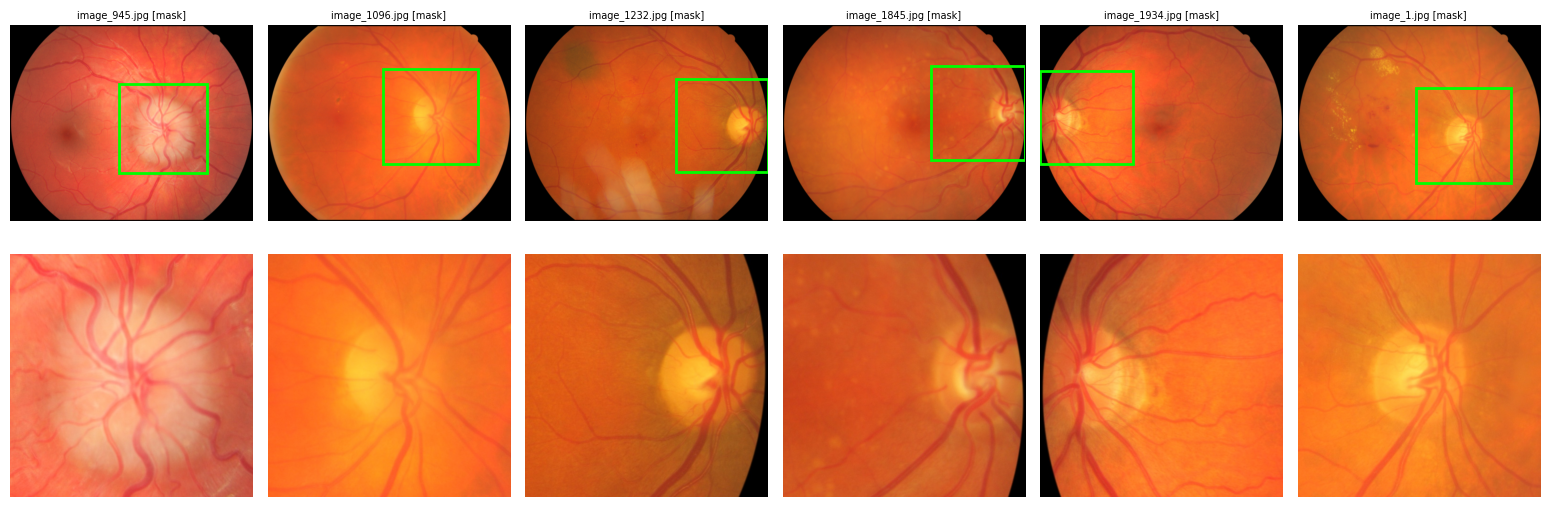

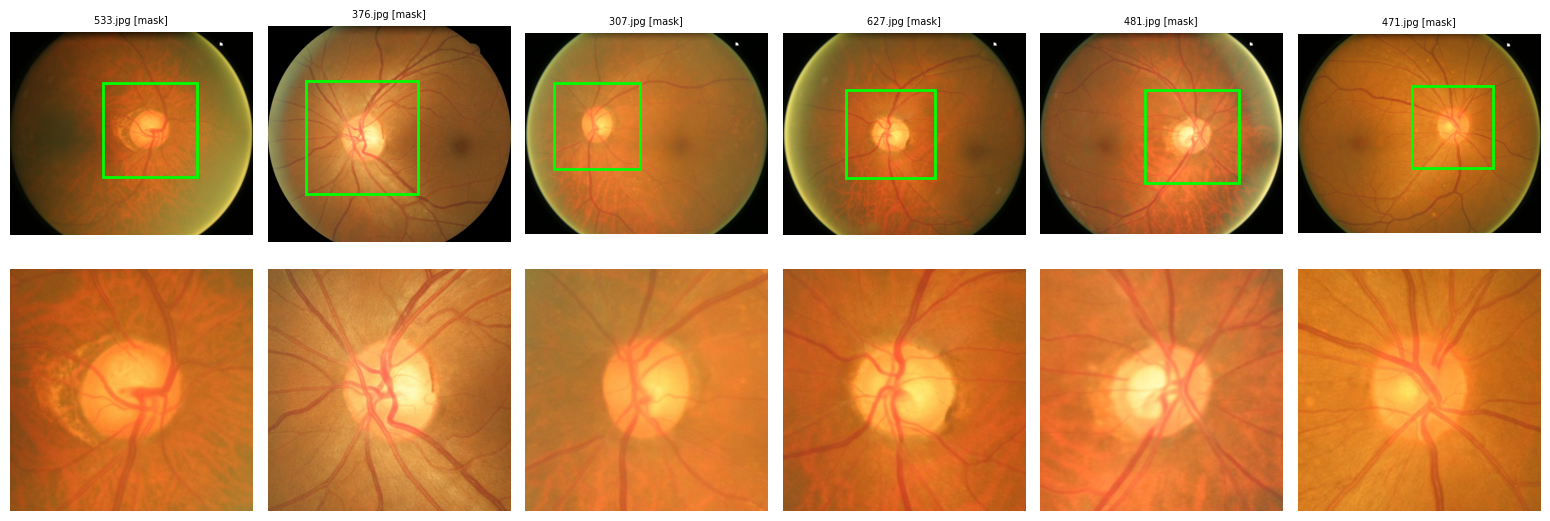

In [ ]:
preview('G1020')
preview('ORIGA')
# Check: the whole optic disc (bright round area where the vessels start) is inside the green box
# and roughly centred, in every example.
#   preview('G1020', seed=1)        -> other random samples (repeat with seeds 2, 3, ...)
#   preview('G1020', flagged=True)  -> only the suspicious crops
#   sheet('G1020', page=0)          -> 40 crops per page, to scan all of them (page 0, 1, 2, ...)
# If a few are wrong: add their centres to MANUAL_CENTERS (block 1), re-run block 1, 2 and 4.
# If MANY are wrong, tell me: the automatic detector is not good enough for your images.